In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score


df = pd.read_csv("Data2.csv")
display(df.head())

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [18]:
X = df.drop("PE", axis=1)
y = df["PE"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)


train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [20]:
# Define our ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),
    
            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),
    
            # output layer
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)

In [21]:
model = ANN()
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [22]:
# Train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # tot training loss for 1 epoch
    
    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch
        optimizer.zero_grad()
        
        outputs = model(xb) # forward prop....predicted outputs for this batch
        loss = crietrion(outputs, yb) # compute loss
        loss.backward() # back prop.. compute gradients
        optimizer.step() # params update
        
        running_loss += loss.item() # loss is a tensor => py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)


    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") #.pt or .pth

epoch 1/100 ==> train loss = 206008.30533854166 & val loss = 203703.765625
epoch 2/100 ==> train loss = 194481.33958333332 & val loss = 179470.03125
epoch 3/100 ==> train loss = 153632.27171223957 & val loss = 123648.359375
epoch 4/100 ==> train loss = 91748.65486653645 & val loss = 62771.625
epoch 5/100 ==> train loss = 43558.95786946615 & val loss = 30246.455078125
epoch 6/100 ==> train loss = 24971.3772664388 & val loss = 21420.587890625
epoch 7/100 ==> train loss = 19696.628373209634 & val loss = 17713.177734375
epoch 8/100 ==> train loss = 16256.757446289062 & val loss = 14427.765625
epoch 9/100 ==> train loss = 12944.631508382161 & val loss = 11200.3056640625
epoch 10/100 ==> train loss = 9777.511305745442 & val loss = 8164.56884765625
epoch 11/100 ==> train loss = 6887.27173055013 & val loss = 5495.90380859375
epoch 12/100 ==> train loss = 4441.1941324869795 & val loss = 3358.342041015625
epoch 13/100 ==> train loss = 2604.332242838542 & val loss = 1879.725341796875
epoch 14/100

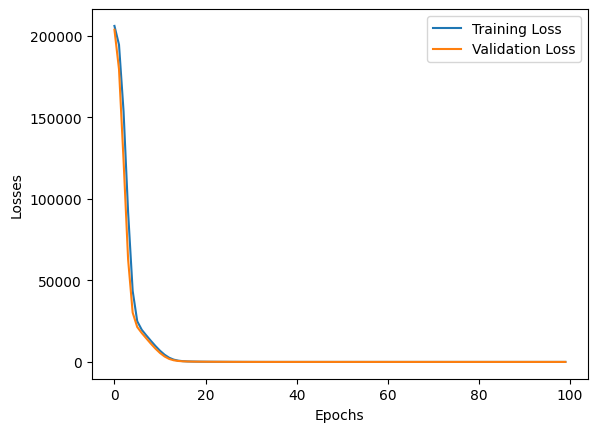

In [23]:
loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

In [24]:
# Model Serialization
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [25]:
# Model Evaluation

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())
print("r^2 score =", r2_score(y_test, test_preds))

Training MSE: 19.456567764282227
Testing MSE: 17.818405151367188
r^2 score = 0.9377292706741951


In [26]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,434.340149,433.27
1,435.881836,438.16
2,461.280762,458.42
3,476.639435,480.82
4,434.416687,441.41
...,...,...
1909,450.876984,456.70
1910,431.499786,438.04
1911,467.675354,467.80
1912,432.680725,437.14
